In [2]:
import os
import numpy as np
from PIL import Image

import pywt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import torchvision.models as models


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


### Image processing (data)

### The CNN Structrue (ResNet50)

### Train and validation loop

In [6]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for W_sel, labels in loader:  # W_sel: [B, C_keep, H_sub, W_sub]
        W_sel = W_sel.to(device).float()
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(W_sel)  # [B, num_classes]
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss / total, (correct / total)*100


def eval_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for W_sel, labels in loader:
            W_sel = W_sel.to(device).float()
            labels = labels.to(device)

            outputs = model(W_sel)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss / total, (correct / total)*100

### Train the model 

In [10]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader



data_root = '/Users/amani.khalid/Desktop/SRP 2/Rock Data/train'  # update this

# ImageNet normalization (required for pretrained ResNet)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Transforms
train_transforms = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

val_transforms = transforms.Compose([
    transforms.Resize((448,448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Datasets
train_dataset = datasets.ImageFolder(root='/Users/amani.khalid/Desktop/SRP 2/Rock Data/train',
                                     transform=train_transforms)

val_dataset = datasets.ImageFolder(root='/Users/amani.khalid/Desktop/SRP 2/Rock Data/val',
                                   transform=val_transforms)

test_dataset = datasets.ImageFolder(root='/Users/amani.khalid/Desktop/SRP 2/Rock Data/test',
                                    transform=val_transforms)

# DataLoaders
train_loader = DataLoader(train_dataset,
                          batch_size=32,
                          shuffle=True,
                          num_workers=4,
                          pin_memory=True)

val_loader = DataLoader(val_dataset,
                        batch_size=32,
                        shuffle=False,
                        num_workers=4,
                        pin_memory=True)

test_loader = DataLoader(test_dataset,
                         batch_size=32,
                         shuffle=False,
                         num_workers=4,
                         pin_memory=True)

# Check classes
print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))


train_acc_list = []
val_acc_list = []

train_loss_list = []
val_loss_list = []


# Load pretrained ResNet50
model = models.resnet50(pretrained=True)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 12)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+1}/{20}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")



Classes: ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']
Number of classes: 12


python(3564) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3567) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3570) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3576) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(15960) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(15961) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(15962) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(15963) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Epoch 1/20: Train loss: 1.9858, acc: 30.23%  | Val loss 1.7286, acc: 33.33%


python(16107) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(16118) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(16127) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(16130) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(22016) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(22017) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(22018) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(22019) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Epoch 2/20: Train loss: 1.6943, acc: 39.39%  | Val loss 1.7126, acc: 43.49%


...

Epoch 18/20: Train loss: 0.5395, acc: 81.55%  | Val loss 1.4704, acc: 60.16%


python(35182) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(35185) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(35188) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(35191) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(43974) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(43975) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(43976) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(43977) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Epoch 19/20: Train loss: 0.4527, acc: 84.34%  | Val loss 1.4807, acc: 65.10%


python(44250) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44253) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44256) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44259) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47056) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47057) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47058) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47059) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Epoch 20/20: Train loss: 0.4431, acc: 84.24%  | Val loss 1.4693, acc: 66.41%


In [12]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [14]:
from torchsummary import summary
summary(model, input_size=(3, 448,448))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]           9,408
       BatchNorm2d-2         [-1, 64, 224, 224]             128
              ReLU-3         [-1, 64, 224, 224]               0
         MaxPool2d-4         [-1, 64, 112, 112]               0
            Conv2d-5         [-1, 64, 112, 112]           4,096
       BatchNorm2d-6         [-1, 64, 112, 112]             128
              ReLU-7         [-1, 64, 112, 112]               0
            Conv2d-8         [-1, 64, 112, 112]          36,864
       BatchNorm2d-9         [-1, 64, 112, 112]             128
             ReLU-10         [-1, 64, 112, 112]               0
           Conv2d-11        [-1, 256, 112, 112]          16,384
      BatchNorm2d-12        [-1, 256, 112, 112]             512
           Conv2d-13        [-1, 256, 112, 112]          16,384
      BatchNorm2d-14        [-1, 256, 1

In [16]:
for epoch in range(30):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+20}/{50}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")



python(47758) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47761) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47764) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47767) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


KeyboardInterrupt: 

 Average accuracy on validation set is 53.8671875


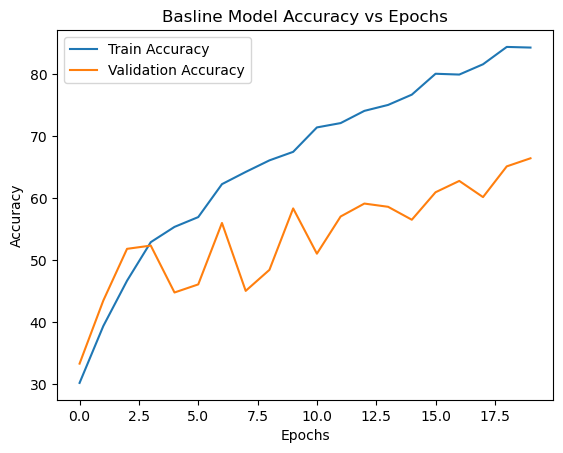

In [20]:
import matplotlib.pyplot as plt

avg_val_acc = sum(val_acc_list)/20
print(f' Average accuracy on validation set is {avg_val_acc}')

plt.title('Basline Model Accuracy vs Epochs')
plt.plot(train_acc_list, label='Train Accuracy')
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [22]:
# Final test evaluation
test_loss, test_acc = eval_one_epoch(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}%")

python(49463) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(49464) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(49465) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(49466) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Test loss: 1.3294, Test acc: 67.6190%


In [24]:
import torch

# after training finishes

torch.save({
    "model_state": model.state_dict()}, "baseline_model_new.pth")

In [26]:
# Check classes
print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))


for epoch in range(30):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+21}/{50}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")


Classes: ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']
Number of classes: 12


python(51036) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51050) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51054) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51057) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


KeyboardInterrupt: 

In [ ]:
# Final test evaluation
test_loss, test_acc = eval_one_epoch(model2, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}%")

In [ ]:
import matplotlib.pyplot as plt

avg_val_acc2 = sum(val_acc_list2)/100
print(f' Average accuracy on validation set is {avg_val_acc}')

plt.title('Model 2 Accuracy vs Epochs')
plt.plot(train_acc_list2, label='Train Accuracy')
plt.plot(val_acc_list2, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

python(52746) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52747) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52748) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52749) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


[[31  0  0  0  2  1  0  0  0  1  1  3]
 [ 0 10  3  0  0  0  0  0  0  0  0  0]
 [ 0  2  9  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  6  0  0  0  0  0  0  0  0]
 [ 3  0  0  0 23  0  3  1  0  2  0  0]
 [ 1  0  0  0  1 20  1  1  0  6  0  4]
 [ 0  0  0  0  2  2 27  4  1  2  2  0]
 [ 3  0  0  0  9  3  3 17  0  5  1  0]
 [ 1  0  0  0  1  6  4  0 18  5  1  2]
 [ 4  0  0  0  3  4  1  4  2 24  1  2]
 [ 2  0  0  0  3  1  1  0  5  9 16  2]
 [ 0  0  0  0  1  0  0  0  0  0  0 42]]


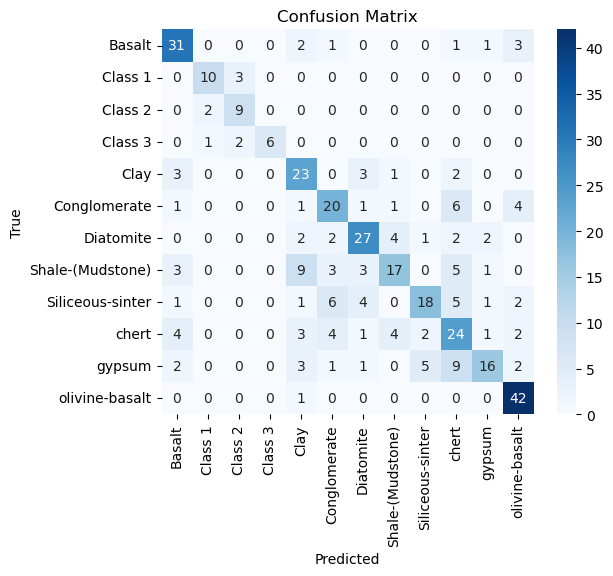

In [30]:
import torch
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in val_loader:   # or test_loader
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

cm = confusion_matrix(all_labels, all_preds)
print(cm)


plt.figure(figsize=(6,5))
class_names = ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [32]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names
))

                  precision    recall  f1-score   support

          Basalt       0.69      0.79      0.74        39
         Class 1       0.77      0.77      0.77        13
         Class 2       0.64      0.82      0.72        11
         Class 3       1.00      0.67      0.80         9
            Clay       0.51      0.72      0.60        32
    Conglomerate       0.54      0.59      0.56        34
       Diatomite       0.68      0.68      0.68        40
Shale-(Mudstone)       0.63      0.41      0.50        41
Siliceous-sinter       0.69      0.47      0.56        38
           chert       0.44      0.53      0.48        45
          gypsum       0.73      0.41      0.52        39
  olivine-basalt       0.76      0.98      0.86        43

        accuracy                           0.63       384
       macro avg       0.67      0.65      0.65       384
    weighted avg       0.65      0.63      0.63       384



### Fine-tuning on a new local dataset with Stratified Cross-Validation

This section adapts the same **cross-validation fine-tuning workflow** used in the CV notebook to the **baseline ResNet50 model**.

It uses the same necessary training augmentations on the training folds:
- `Resize((224, 224))`
- `RandomHorizontalFlip(p=0.5)`
- `RandomVerticalFlip(p=0.2)`
- `RandomRotation(10)`

Recommended schedule:
- **Stage 1:** train classifier head only
- **Stage 2:** unfreeze `layer4` with a smaller learning rate
- **Evaluation:** pooled fold metrics + confusion matrix


In [38]:
from copy import deepcopy
from pathlib import Path
import copy
import json
import random

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score
from torch.utils.data import DataLoader, Subset


In [40]:
# ===== USER SETTINGS =====
pretrained_ckpt_path = '/Users/amani.khalid/Desktop/SRP 2/The model/baseline_model_new.pth'  # <- update this
new_data_root = '/Users/amani.khalid/Desktop/SRP 2/Real data/new/train'                   # <- update this
save_dir = '/Users/amani.khalid/Desktop/SRP 2/The model/baseline_finetune_cv'             # <- update this

deployment_test_root = '/Users/amani.khalid/Desktop/SRP 2/Real data/new/test'             # <- update this

# Cross-validation setup
n_splits = 5
random_state = 42
batch_size = 8
num_workers = 0

# Fine-tuning schedule
head_epochs = 8
full_epochs = 12
head_lr = 1e-3
backbone_lr = 1e-5
weight_decay = 1e-4
patience = 5

# ImageNet normalization (required for pretrained ResNet)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

print('Config loaded.')


Config loaded.


In [42]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(random_state)
os.makedirs(save_dir, exist_ok=True)


In [44]:
# Same necessary augmentation policy as the CV notebook
train_transform_cv = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

val_transform_cv = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])


In [46]:
class IndexedImageFolder(ImageFolder):
    def __getitem__(self, index):
        path, target = self.samples[index]
        sample = self.loader(path)
        if self.transform is not None:
            sample = self.transform(sample)
        if self.target_transform is not None:
            target = self.target_transform(target)
        return sample, target, index


def build_fold_dataloaders(indexed_ds, train_idx, val_idx, batch_size=8, num_workers=0):
    train_ds = copy.deepcopy(indexed_ds)
    val_ds = copy.deepcopy(indexed_ds)

    train_ds.transform = train_transform_cv
    val_ds.transform = val_transform_cv

    train_subset = Subset(train_ds, list(train_idx))
    val_subset = Subset(val_ds, list(val_idx))

    train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    return train_loader, val_loader


In [88]:
def load_pretrained_resnet_for_finetune(ckpt_path, num_classes, device, class_mapping=None):
    """
    Load pretrained ResNet and map fc layer weights from 12 classes to 3 classes.
    
    Args:
        ckpt_path: Path to checkpoint with 12 classes
        num_classes: Number of classes in your dataset (should be 3)
        device: Device to load model to
        class_mapping: List of 12 original class names, or dict mapping old indices to new indices
                      Example: [class1, class2, class3, class4, ...] where you want indices 0,1,2
    """
    # Initialize model with ImageNet weights (for backbone)
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    in_features = model.fc.in_features
    
    # Load checkpoint
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    if isinstance(ckpt, dict):
        state_dict = ckpt.get('model_state', ckpt.get('model_state_dict', ckpt))
    else:
        state_dict = ckpt
    
    # Extract the pretrained fc layer weights (shape: [12, 2048])
    pretrained_fc_weight = state_dict['fc.weight']  # [12, 2048]
    pretrained_fc_bias = state_dict['fc.bias']      # [12]
    
    # Create new fc layer for 3 classes
    new_fc = nn.Linear(in_features, num_classes)
    
    # Map weights: take only the first 3 classes (assuming your 3 classes are classes 0,1,2)
    # If your 3 classes are specific indices in the 12, specify the class_mapping
    if class_mapping is None:
        # Assume your 3 classes correspond to indices 0,1,2 in the checkpoint
        mapped_indices = [1,2,3]
    else:
        mapped_indices = class_mapping
    
    # Copy the corresponding weights
    with torch.no_grad():
        new_fc.weight.data = pretrained_fc_weight[mapped_indices, :]  # [3, 2048]
        new_fc.bias.data = pretrained_fc_bias[mapped_indices]          # [3]
    
    print(f"Mapped fc layer from 12 classes to {num_classes} classes")
    print(f"Used checkpoint indices: {mapped_indices}")
    print(f"Original fc weight shape: {pretrained_fc_weight.shape}")
    print(f"New fc weight shape: {new_fc.weight.shape}")
    
    # Replace fc layer in model
    model.fc = new_fc
    
    # Remove fc layer keys from state_dict (already handled manually)
    filtered_state_dict = {k: v for k, v in state_dict.items() if not k.startswith('fc.')}
    
    # Load backbone weights
    missing, unexpected = model.load_state_dict(filtered_state_dict, strict=False)
    print('Loaded checkpoint:', ckpt_path)
    print('Missing keys (expected: none for backbone):', [k for k in missing if not k.startswith('fc.')])
    
    return model.to(device)

def freeze_backbone_train_head(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True


def unfreeze_last_block(model):
    for param in model.layer4.parameters():
        param.requires_grad = True
    for param in model.fc.parameters():
        param.requires_grad = True


def make_optimizer_stage1(model):
    return optim.Adam(
        model.fc.parameters(),
        lr=head_lr,
        weight_decay=weight_decay,
    )


def make_optimizer_stage2(model):
    params = [
        {'params': model.layer4.parameters(), 'lr': backbone_lr},
        {'params': model.fc.parameters(), 'lr': head_lr},
    ]
    return optim.Adam(params, weight_decay=weight_decay)


In [90]:
def predict_on_loader(model, loader, device):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            x = x.to(device)
            outputs = model(x)
            preds = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(preds.tolist())
            y_true.extend(y.numpy().tolist())
    return np.array(y_true), np.array(y_pred)


def run_training_stage(model, train_loader, val_loader, optimizer, criterion, epochs, device,
                       best_state=None, best_val=-1.0, patience=5):
    train_hist, val_hist = [], []
    stale_epochs = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_cv(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = eval_one_epoch_cv(model, val_loader, criterion, device)

        train_hist.append({'loss': train_loss, 'acc': train_acc})
        val_hist.append({'loss': val_loss, 'acc': val_acc})

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"train loss={train_loss:.4f}, train acc={train_acc:.2f}% | "
            f"val loss={val_loss:.4f}, val acc={val_acc:.2f}%"
        )

        if val_acc > best_val:
            best_val = val_acc
            best_state = deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= patience:
                print(f'Early stopping triggered after {epoch + 1} epochs.')
                break

    return best_state, best_val, train_hist, val_hist


In [92]:
# Build full dataset from the NEW local data
indexed_ds = IndexedImageFolder(new_data_root)
labels = np.array(indexed_ds.targets)
class_names = indexed_ds.classes
num_classes = len(class_names)

print('Classes:', class_names)
print('Total images:', len(indexed_ds))
print('Class counts:', {class_names[i]: int((labels == i).sum()) for i in range(num_classes)})

min_class_count = min(int((labels == i).sum()) for i in range(num_classes))
actual_splits = min(n_splits, min_class_count)
if actual_splits < 2:
    raise ValueError('Need at least 2 images in every class for cross-validation.')

print(f'Using StratifiedKFold with n_splits={actual_splits}')
skf = StratifiedKFold(n_splits=actual_splits, shuffle=True, random_state=random_state)


Classes: ['Class 1', 'Class 2', 'Class 3']
Total images: 188
Class counts: {'Class 1': 72, 'Class 2': 65, 'Class 3': 51}
Using StratifiedKFold with n_splits=5


In [103]:
def train_one_epoch_cv(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for batch in loader:
        # Handle both formats
        if isinstance(batch, (list, tuple)):
            if len(batch) == 3:
                x, y, _ = batch
            else:
                x, y = batch
        else:
            x, y = batch, None  # Fallback
        
        x = x.to(device)
        y = y.to(device)
        
        optimizer.zero_grad()
        outputs = model(x)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * x.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == y).sum().item()
        total += x.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    return epoch_loss, epoch_acc


def eval_one_epoch_cv(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for batch in loader:
            # Handle both formats
            if isinstance(batch, (list, tuple)):
                if len(batch) == 3:
                    x, y, _ = batch
                else:
                    x, y = batch
            else:
                x, y = batch, None
            
            x = x.to(device)
            y = y.to(device)
            
            outputs = model(x)
            loss = criterion(outputs, y)
            
            running_loss += loss.item() * x.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == y).sum().item()
            total += x.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    return epoch_loss, epoch_acc

In [94]:
fold_results = []
all_fold_labels = []
all_fold_preds = []
criterion = nn.CrossEntropyLoss()

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(labels)), labels), start=1):
    print('=' * 80)
    print(f'FOLD {fold}/{actual_splits}')
    print('=' * 80)

    train_loader_cv, val_loader_cv = build_fold_dataloaders(
        indexed_ds=indexed_ds,
        train_idx=train_idx,
        val_idx=val_idx,
        batch_size=batch_size,
        num_workers=num_workers,
    )

    model_ft = load_pretrained_resnet_for_finetune(
        ckpt_path=pretrained_ckpt_path,
        num_classes=num_classes,
        device=device,
    )

    freeze_backbone_train_head(model_ft)
    optimizer = make_optimizer_stage1(model_ft)
    best_state = None
    best_val = -1.0

    print('Stage 1: head-only fine-tuning')
    best_state, best_val, hist1_train, hist1_val = run_training_stage(
        model_ft, train_loader_cv, val_loader_cv, optimizer, criterion,
        epochs=head_epochs, device=device,
        best_state=best_state, best_val=best_val, patience=patience,
    )

    model_ft.load_state_dict(best_state)
    unfreeze_last_block(model_ft)
    optimizer = make_optimizer_stage2(model_ft)

    print('Stage 2: unfreeze layer4 + classifier')
    best_state, best_val, hist2_train, hist2_val = run_training_stage(
        model_ft, train_loader_cv, val_loader_cv, optimizer, criterion,
        epochs=full_epochs, device=device,
        best_state=best_state, best_val=best_val, patience=patience,
    )

    model_ft.load_state_dict(best_state)

    y_true, y_pred = predict_on_loader(model_ft, val_loader_cv, device)
    val_acc = 100.0 * (y_true == y_pred).mean()
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')
    balanced_acc = balanced_accuracy_score(y_true, y_pred)

    fold_ckpt_path = os.path.join(save_dir, f'baseline_fold_{fold}.pth')
    torch.save({
        'model_state': model_ft.state_dict(),
        'class_names': class_names,
        'num_classes': num_classes,
        'fold': fold,
        'val_acc': val_acc,
        'weighted_f1': weighted_f1,
        'balanced_acc': balanced_acc,
    }, fold_ckpt_path)

    print(f'Fold {fold} val acc: {val_acc:.2f}%')
    print(f'Fold {fold} weighted F1: {weighted_f1:.4f}')
    print(f'Fold {fold} balanced acc: {balanced_acc:.4f}')

    fold_results.append({
        'fold': fold,
        'n_train': len(train_idx),
        'n_val': len(val_idx),
        'val_acc': val_acc,
        'weighted_f1': weighted_f1,
        'balanced_acc': balanced_acc,
        'checkpoint_path': fold_ckpt_path,
    })

    all_fold_labels.extend(y_true.tolist())
    all_fold_preds.extend(y_pred.tolist())


FOLD 1/5
Mapped fc layer from 12 classes to 3 classes
Used checkpoint indices: [1, 2, 3]
Original fc weight shape: torch.Size([12, 2048])
New fc weight shape: torch.Size([3, 2048])
Loaded checkpoint: /Users/amani.khalid/Desktop/SRP 2/The model/baseline_model_new.pth
Missing keys (expected: none for backbone): []
Stage 1: head-only fine-tuning
Epoch 1/8: train loss=1.1586, train acc=58.67% | val loss=1.9047, val acc=34.21%
Epoch 2/8: train loss=0.9775, train acc=55.33% | val loss=1.4990, val acc=47.37%
Epoch 3/8: train loss=0.7884, train acc=66.00% | val loss=1.1890, val acc=50.00%
Epoch 4/8: train loss=0.8230, train acc=64.00% | val loss=1.1520, val acc=50.00%
Epoch 5/8: train loss=0.6875, train acc=72.67% | val loss=1.1457, val acc=60.53%
Epoch 6/8: train loss=0.7312, train acc=67.33% | val loss=1.1046, val acc=60.53%
Epoch 7/8: train loss=0.6729, train acc=65.33% | val loss=1.0682, val acc=65.79%
Epoch 8/8: train loss=0.6804, train acc=62.67% | val loss=1.0287, val acc=60.53%
Stage 2

In [96]:
results_df = pd.DataFrame(fold_results)
display(results_df)

print('Mean CV accuracy:      {:.2f}% +- {:.2f}'.format(
    results_df['val_acc'].mean(),
    results_df['val_acc'].std(ddof=1) if len(results_df) > 1 else 0.0,
))
print('Mean CV weighted F1:   {:.4f} +- {:.4f}'.format(
    results_df['weighted_f1'].mean(),
    results_df['weighted_f1'].std(ddof=1) if len(results_df) > 1 else 0.0,
))
print('Mean CV balanced acc:  {:.4f} +- {:.4f}'.format(
    results_df['balanced_acc'].mean(),
    results_df['balanced_acc'].std(ddof=1) if len(results_df) > 1 else 0.0,
))


,fold,n_train,n_val,val_acc,weighted_f1,balanced_acc,checkpoint_path
0,1,150,38,68.421053,0.679825,0.657265,/Users/amani.khalid/Desktop/SRP 2/The model/ba...
1,2,150,38,84.210526,0.841192,0.829915,/Users/amani.khalid/Desktop/SRP 2/The model/ba...
2,3,150,38,76.315789,0.748606,0.777389,/Users/amani.khalid/Desktop/SRP 2/The model/ba...
3,4,151,37,72.972973,0.709723,0.742857,/Users/amani.khalid/Desktop/SRP 2/The model/ba...
4,5,151,37,67.567568,0.671171,0.689744,/Users/amani.khalid/Desktop/SRP 2/The model/ba...


Mean CV accuracy:      73.90% +- 6.77
Mean CV weighted F1:   0.7301 +- 0.0691
Mean CV balanced acc:  0.7394 +- 0.0687


[[47 11 14]
 [10 54  1]
 [10  3 38]]


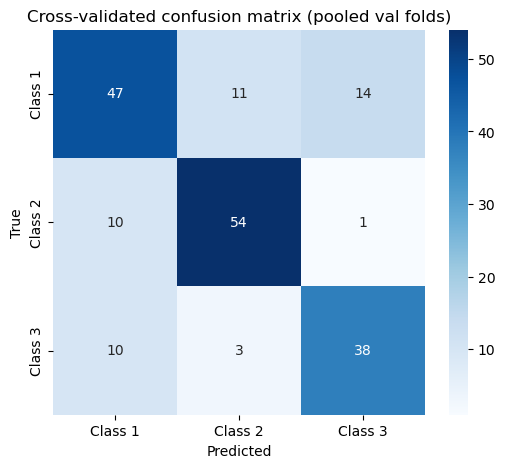

              precision    recall  f1-score   support

     Class 1       0.70      0.65      0.68        72
     Class 2       0.79      0.83      0.81        65
     Class 3       0.72      0.75      0.73        51

    accuracy                           0.74       188
   macro avg       0.74      0.74      0.74       188
weighted avg       0.74      0.74      0.74       188



In [98]:
all_fold_labels = np.array(all_fold_labels)
all_fold_preds = np.array(all_fold_preds)

cm = confusion_matrix(all_fold_labels, all_fold_preds)
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Cross-validated confusion matrix (pooled val folds)')
plt.show()

print(classification_report(all_fold_labels, all_fold_preds, target_names=class_names))


### Post-CV deployment stage

Retrain one final model on **all training data**, using the same augmentation policy, and then evaluate once on a completely separate held-out test folder.

In [105]:
best_fold = max(
    fold_results,
    key=lambda x: (x['balanced_acc'], x['weighted_f1'], x['val_acc'])
)
print('Selected best CV fold:')
print(best_fold)

full_train_ds = datasets.ImageFolder(root=new_data_root, transform=train_transform_cv)
deployment_test_ds = datasets.ImageFolder(root=deployment_test_root, transform=val_transform_cv)

full_train_loader = DataLoader(
    full_train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)
deployment_test_loader = DataLoader(
    deployment_test_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

final_model = load_pretrained_resnet_for_finetune(
    ckpt_path=pretrained_ckpt_path,
    num_classes=num_classes,
    device=device,
)

freeze_backbone_train_head(final_model)
optimizer = make_optimizer_stage1(final_model)
best_state = None
best_val = -1.0

print('Final training - Stage 1: head-only fine-tuning')
best_state, best_val, _, _ = run_training_stage(
    final_model, full_train_loader, deployment_test_loader, optimizer, criterion,
    epochs=head_epochs, device=device,
    best_state=best_state, best_val=best_val, patience=patience,
)

final_model.load_state_dict(best_state)
unfreeze_last_block(final_model)
optimizer = make_optimizer_stage2(final_model)

print('Final training - Stage 2: unfreeze layer4 + classifier')
best_state, best_val, _, _ = run_training_stage(
    final_model, full_train_loader, deployment_test_loader, optimizer, criterion,
    epochs=full_epochs, device=device,
    best_state=best_state, best_val=best_val, patience=patience,
)

final_model.load_state_dict(best_state)


Selected best CV fold:
{'fold': 2, 'n_train': 150, 'n_val': 38, 'val_acc': 84.21052631578947, 'weighted_f1': 0.8411915204678363, 'balanced_acc': 0.82991452991453, 'checkpoint_path': '/Users/amani.khalid/Desktop/SRP 2/The model/baseline_finetune_cv/baseline_fold_2.pth'}
Mapped fc layer from 12 classes to 3 classes
Used checkpoint indices: [1, 2, 3]
Original fc weight shape: torch.Size([12, 2048])
New fc weight shape: torch.Size([3, 2048])
Loaded checkpoint: /Users/amani.khalid/Desktop/SRP 2/The model/baseline_model_new.pth
Missing keys (expected: none for backbone): []
Final training - Stage 1: head-only fine-tuning
Epoch 1/8: train loss=1.0785, train acc=56.91% | val loss=1.3909, val acc=52.63%
Epoch 2/8: train loss=0.8233, train acc=65.43% | val loss=0.9796, val acc=65.79%
Epoch 3/8: train loss=0.8096, train acc=62.23% | val loss=0.8841, val acc=57.89%
Epoch 4/8: train loss=0.7875, train acc=62.23% | val loss=0.8024, val acc=60.53%
Epoch 5/8: train loss=0.7418, train acc=65.96% | val 

<All keys matched successfully>

In [107]:
final_model_path = os.path.join(save_dir, 'baseline_final_deployment_model.pth')
final_metrics_path = os.path.join(save_dir, 'baseline_final_deployment_metrics.json')

test_loss, test_acc = eval_one_epoch(final_model, deployment_test_loader, criterion, device)
y_true_test = []
y_pred_test = []

final_model.eval()
with torch.no_grad():
    for x, y in deployment_test_loader:
        x = x.to(device)
        outputs = final_model(x)
        preds = outputs.argmax(dim=1).cpu().numpy()
        y_pred_test.extend(preds.tolist())
        y_true_test.extend(y.numpy().tolist())

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)

deployment_metrics = {
    'test_loss': float(test_loss),
    'test_acc': float(test_acc),
    'weighted_f1': float(f1_score(y_true_test, y_pred_test, average='weighted')),
    'balanced_acc': float(balanced_accuracy_score(y_true_test, y_pred_test)),
    'class_names': class_names,
}

print(deployment_metrics)

torch.save({
    'model_state': final_model.state_dict(),
    'class_names': class_names,
    'num_classes': num_classes,
    'metrics': deployment_metrics,
}, final_model_path)

with open(final_metrics_path, 'w') as f:
    json.dump(deployment_metrics, f, indent=2)

print(f'Saved final model to: {final_model_path}')
print(f'Saved metrics to: {final_metrics_path}')


{'test_loss': 0.5100679711291665, 'test_acc': 78.94736842105263, 'weighted_f1': 0.7932066474502687, 'balanced_acc': 0.8075142450142451, 'class_names': ['Class 1', 'Class 2', 'Class 3']}
Saved final model to: /Users/amani.khalid/Desktop/SRP 2/The model/baseline_finetune_cv/baseline_final_deployment_model.pth
Saved metrics to: /Users/amani.khalid/Desktop/SRP 2/The model/baseline_finetune_cv/baseline_final_deployment_metrics.json


In [113]:
# ------------------------------------------------------------
# EVALUATE ON HELD-OUT TEST SET
# ------------------------------------------------------------

test_acc = (y_true_test == y_pred_test).mean() * 100.0
test_f1 = f1_score(y_true_test, y_pred_test, average='weighted', zero_division=0)
test_bal_acc = balanced_accuracy_score(y_true_test, y_pred_test)
test_cm = confusion_matrix(y_true_test, y_pred_test)

print('\n' + '=' * 80)
print('FINAL HELD-OUT TEST RESULTS')
print('=' * 80)
print(f'Test Accuracy     : {test_acc:.2f}%')
print(f'Test Weighted F1  : {test_f1:.4f}')
print(f'Test Balanced Acc : {test_bal_acc:.4f}')
print('\nConfusion Matrix:')
print(test_cm)

print('\nClassification Report:')
print(classification_report(
    y_true_test,
    y_pred_test,
    target_names=class_names,
    zero_division=0
))



FINAL HELD-OUT TEST RESULTS
Test Accuracy     : 78.95%
Test Weighted F1  : 0.7932
Test Balanced Acc : 0.8075

Confusion Matrix:
[[11  5  0]
 [ 2 11  0]
 [ 0  1  8]]

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.85      0.69      0.76        16
     Class 2       0.65      0.85      0.73        13
     Class 3       1.00      0.89      0.94         9

    accuracy                           0.79        38
   macro avg       0.83      0.81      0.81        38
weighted avg       0.81      0.79      0.79        38



[[11  5  0]
 [ 2 11  0]
 [ 0  1  8]]


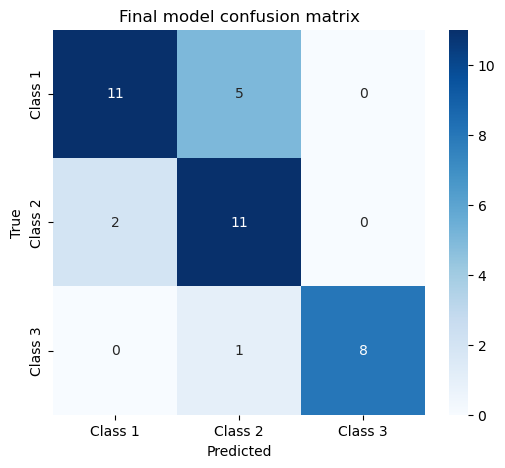

In [115]:
cm1 = confusion_matrix(y_true_test, y_pred_test )
print(cm1)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Final model confusion matrix')
plt.show()



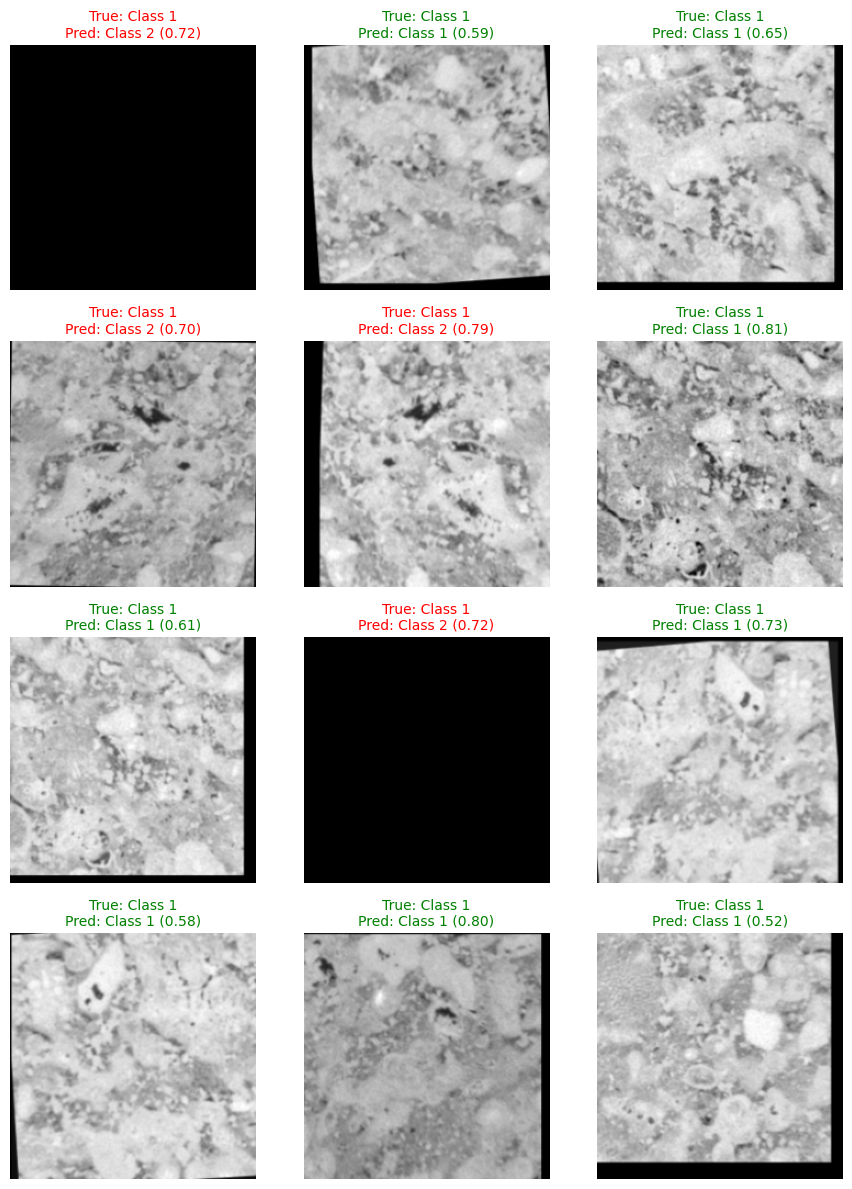

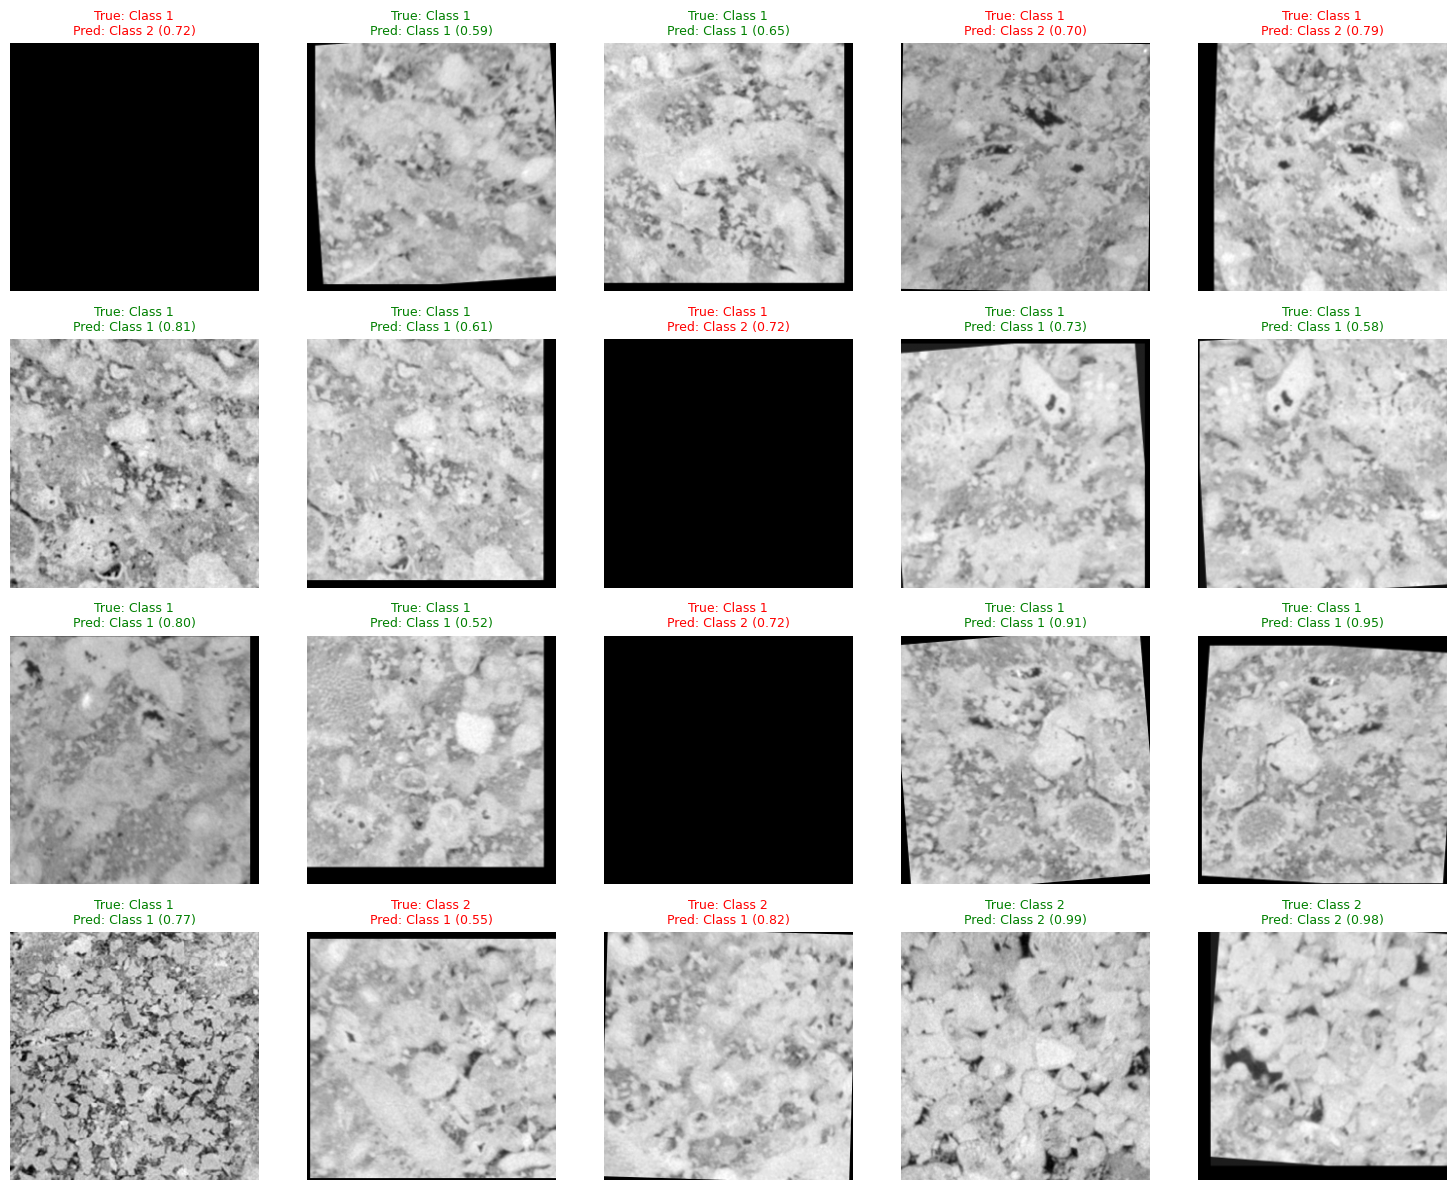

Total misclassified: 8/38


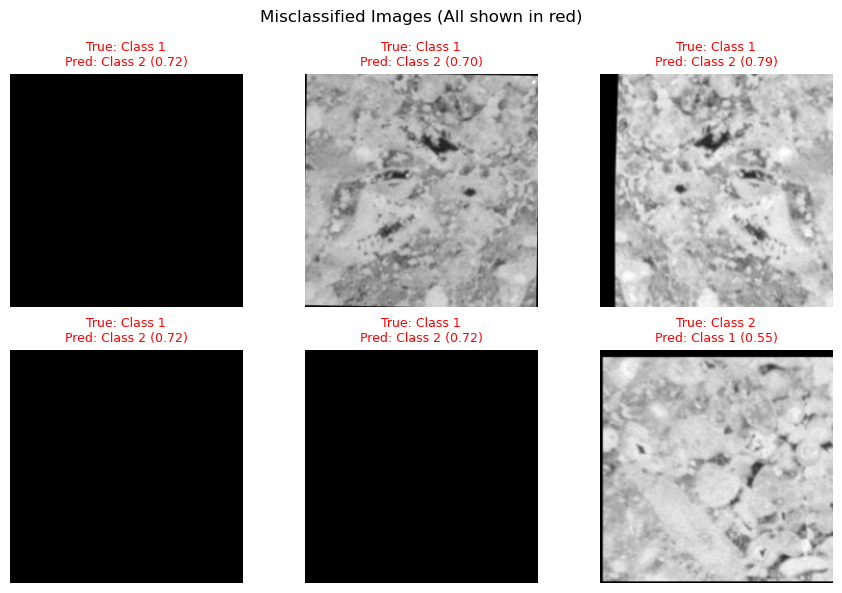

In [133]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def denormalize_image(image_tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    """
    Denormalize an image tensor that was normalized with ImageNet stats.
    Returns a numpy array ready for display.
    """
    # Make a copy to avoid modifying original
    img = image_tensor.cpu().clone()
    
    # Denormalize: x = x * std + mean
    for t, m, s in zip(img, mean, std):
        t.mul_(s).add_(m)
    
    # Clamp to [0,1]
    img = torch.clamp(img, 0, 1)
    
    # Convert RGB to grayscale using luminance formula
    # Y = 0.299R + 0.587G + 0.114B
    gray = 0.299 * img[0] + 0.587 * img[1] + 0.114 * img[2]
    
    return gray.numpy()


def predict_and_display_grayscale(model, dataset, indices, class_names, device, num_images=9):
    """
    Display grayscale images with true and predicted labels.
    Green title = correct prediction, Red title = incorrect prediction.
    
    Args:
        model: Trained PyTorch model
        dataset: Test dataset (ImageFolder or similar)
        indices: List of image indices to display
        class_names: List of class names
        device: 'cuda' or 'cpu'
        num_images: Number of images to display
    """
    model.eval()
    cols = int(np.sqrt(num_images))
    rows = int(np.ceil(num_images / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    axes = axes.flatten()
    
    for idx, ax in enumerate(axes):
        if idx >= len(indices):
            ax.axis('off')
            continue
            
        img_idx = indices[idx]
        
        # Get image and true label from dataset
        try:
            # For ImageFolder dataset
            if hasattr(dataset, 'samples'):
                img_path, true_label = dataset.samples[img_idx]
                image_tensor, _ = dataset[img_idx]
            elif hasattr(dataset, 'imgs'):
                img_path, true_label = dataset.imgs[img_idx]
                image_tensor, _ = dataset[img_idx]
            else:
                # Direct tensor dataset
                image_tensor, true_label = dataset[img_idx]
                img_path = None
        except:
            image_tensor, true_label = dataset[img_idx]
            img_path = None
        
        # Get prediction
        with torch.no_grad():
            # Ensure image is on correct device and has batch dimension
            if isinstance(image_tensor, torch.Tensor):
                input_tensor = image_tensor.unsqueeze(0).to(device)
            else:
                # If image is not a tensor (shouldn't happen), skip
                ax.axis('off')
                continue
            
            outputs = model(input_tensor)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            pred_label = predicted.item()
            confidence = probs[0][pred_label].item()
        
        # Convert image for grayscale display
        if isinstance(image_tensor, torch.Tensor):
            # Denormalize and convert to grayscale
            img_display = denormalize_image(image_tensor)
        else:
            # Fallback for non-tensor images
            ax.axis('off')
            continue
        
        # Determine color based on correctness
        is_correct = (true_label == pred_label)
        color = 'green' if is_correct else 'red'
        
        # Display grayscale image
        ax.imshow(img_display, cmap='gray')
        ax.set_title(f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})',
                     color=color, fontsize=10)
        ax.axis('off')
    
    # Hide any unused subplots
    for idx in range(len(indices), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()


def predict_and_display_from_paths(model, image_paths, true_labels, class_names, device, transform=None):
    """
    Display grayscale predictions using direct image paths (no preprocessing issues).
    This is the most reliable method.
    
    Args:
        model: Trained PyTorch model
        image_paths: List of image file paths
        true_labels: List of true label indices
        class_names: List of class names
        device: 'cuda' or 'cpu'
        transform: The validation transform to apply for model input
    """
    model.eval()
    num_images = len(image_paths)
    cols = int(np.ceil(np.sqrt(num_images)))
    rows = int(np.ceil(num_images / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    axes = axes.flatten() if num_images > 1 else [axes]
    
    for idx, (img_path, true_label) in enumerate(zip(image_paths, true_labels)):
        # Load original image for display (grayscale)
        original_image = Image.open(img_path).convert('L')  # 'L' = grayscale
        img_display = np.array(original_image)
        
        # Load and preprocess RGB image for model
        rgb_image = Image.open(img_path).convert('RGB')
        if transform:
            preprocessed = transform(rgb_image)
        else:
            # Default: just convert to tensor
            from torchvision import transforms
            preprocessed = transforms.ToTensor()(rgb_image)
        
        preprocessed = preprocessed.unsqueeze(0).to(device)
        
        # Get prediction
        with torch.no_grad():
            outputs = model(preprocessed)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            pred_label = predicted.item()
            confidence = probs[0][pred_label].item()
        
        is_correct = (true_label == pred_label)
        color = 'green' if is_correct else 'red'
        
        axes[idx].imshow(img_display, cmap='gray')
        axes[idx].set_title(f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})',
                            color=color, fontsize=9)
        axes[idx].axis('off')
    
    # Hide unused subplots
    for idx in range(num_images, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()


def show_misclassified_grayscale(model, dataset, class_names, device, num_images=3):
    """
    Display only misclassified images in grayscale.
    """
    model.eval()
    
    # Find all misclassified indices
    misclassified = []
    misclassified_preds = []
    misclassified_confs = []
    
    for idx in range(len(dataset)):
        try:
            if hasattr(dataset, 'samples'):
                _, true_label = dataset.samples[idx]
            else:
                _, true_label = dataset[idx]
            
            image_tensor, _ = dataset[idx]
            input_tensor = image_tensor.unsqueeze(0).to(device)
            
            with torch.no_grad():
                outputs = model(input_tensor)
                probs = torch.softmax(outputs, dim=1)
                _, predicted = torch.max(outputs, 1)
                pred_label = predicted.item()
                confidence = probs[0][pred_label].item()
            
            if true_label != pred_label:
                misclassified.append(idx)
                misclassified_preds.append((pred_label, confidence))
        except:
            continue
    
    print(f"Total misclassified: {len(misclassified)}/{len(dataset)}")
    
    # Display misclassified images
    num_to_show = min(num_images, len(misclassified))
    if num_to_show == 0:
        print("No misclassified images to display!")
        return
    
    cols = int(np.ceil(np.sqrt(num_to_show)))
    rows = int(np.ceil(num_to_show / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    axes = axes.flatten() if num_to_show > 1 else [axes]
    
    for i in range(num_to_show):
        idx = misclassified[i]
        pred_label, confidence = misclassified_preds[i]
        
        # Get true label
        if hasattr(dataset, 'samples'):
            _, true_label = dataset.samples[idx]
        else:
            _, true_label = dataset[idx]
        
        # Get image
        image_tensor, _ = dataset[idx]
        img_display = denormalize_image(image_tensor)
        
        axes[i].imshow(img_display, cmap='gray')
        axes[i].set_title(f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})',
                          color='red', fontsize=9)
        axes[i].axis('off')
    
    # Hide unused subplots
    for i in range(num_to_show, len(axes)):
        axes[i].axis('off')
    
    plt.suptitle('Misclassified Images (All shown in red)', fontsize=12)
    plt.tight_layout()
    plt.show()


# ============= USAGE EXAMPLES =============

# Example 1: Display predictions from dataset indices
class_names = ['Class 1', 'Class 2', 'Class 3']  # Replace with your class names
indices_to_show = list(range(12))  # First 12 test images

predict_and_display_grayscale(
    model=final_model,
    dataset=deployment_test_ds,
    indices=indices_to_show,
    class_names=class_names,
    device=device,
    num_images=12
)

# Example 2: Display from image paths (most reliable for grayscale)
# Get paths and labels from your dataset
test_paths = [deployment_test_ds.samples[i][0] for i in range(20)]
test_labels = [deployment_test_ds.samples[i][1] for i in range(20)]

predict_and_display_from_paths(
    model=final_model,
    image_paths=test_paths[:38],
    true_labels=test_labels[:38],
    class_names=class_names,
    device=device,
    transform=val_transform_cv  # Your validation transform
)

# Example 3: Show only misclassified images
show_misclassified_grayscale(
    model=final_model,
    dataset=deployment_test_ds,
    class_names=class_names,
    device=device,
    num_images=6
)

Checking dataset contents...
Found 9 Class 3 images
First 5 Class 3 image paths:
  [29] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0002-0228_aug_1.png
  [30] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0374_aug_0.png
  [31] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0374_aug_4.png
  [32] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0387.png
  [33] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0387_aug_4.png
Found 9 Class 3 images
First 5 Class 3 image paths:
  [29] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0002-0228_aug_1.png
  [30] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0374_aug_0.png
  [31] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0374_aug_4.png
  [32] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0387.png
  [33] /Users/amani.khalid/Desktop/SRP 2/Real data/new/test/Class 3/0003-0387_aug_4.png

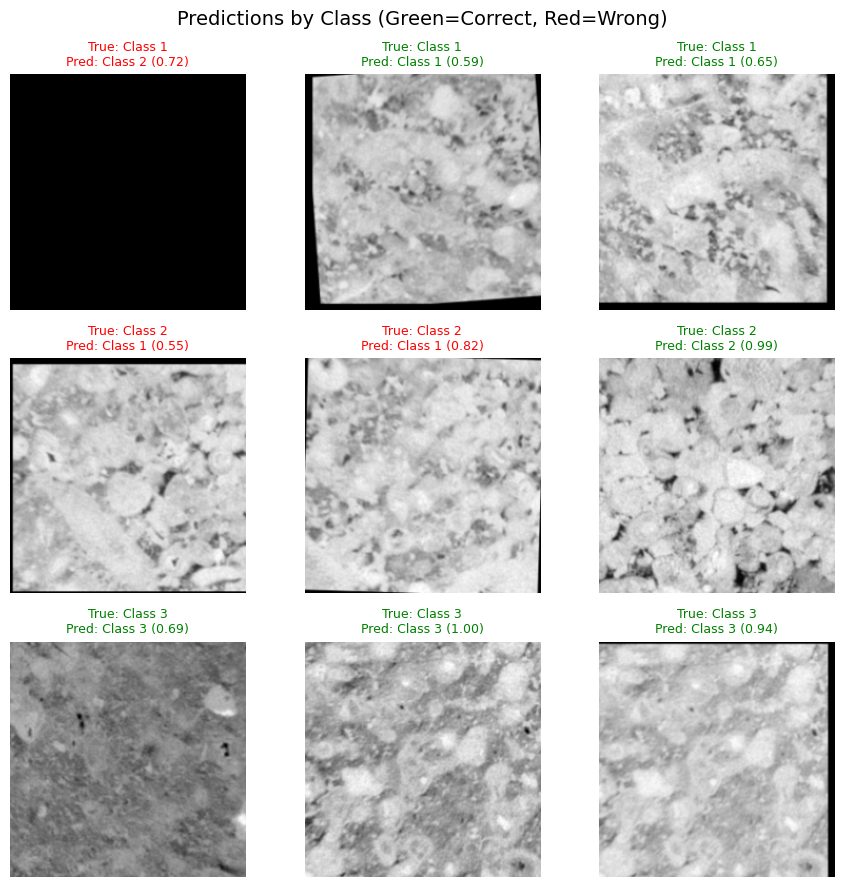


Class 3 indices found: [29, 30, 31, 32, 33, 34, 35, 36, 37]


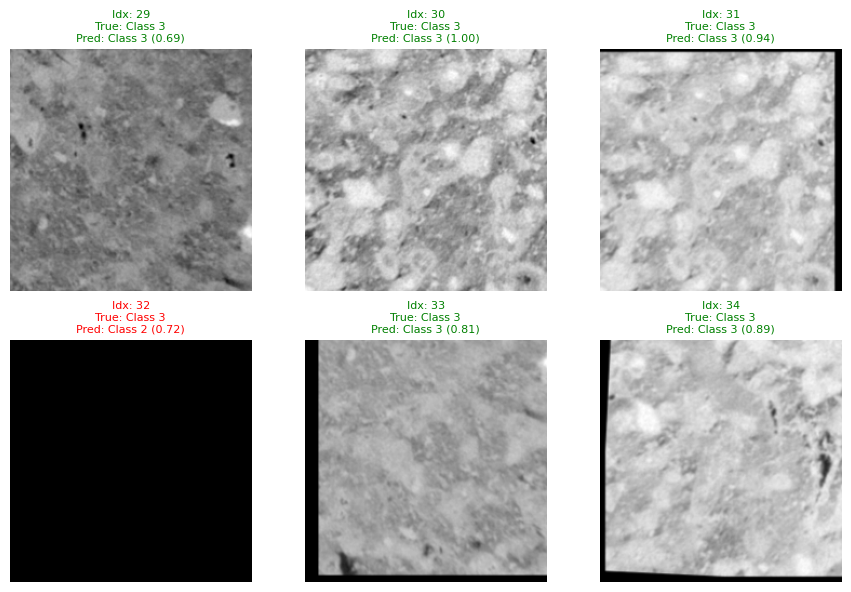

In [135]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def denormalize_image(image_tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    """
    Denormalize an image tensor that was normalized with ImageNet stats.
    Returns a numpy array ready for display.
    """
    img = image_tensor.cpu().clone()
    
    for t, m, s in zip(img, mean, std):
        t.mul_(s).add_(m)
    
    img = torch.clamp(img, 0, 1)
    
    # Convert RGB to grayscale
    gray = 0.299 * img[0] + 0.587 * img[1] + 0.114 * img[2]
    
    return gray.numpy()


def get_indices_for_all_classes(dataset, num_per_class=3):
    """
    Get indices from dataset ensuring representation from all classes.
    
    Args:
        dataset: ImageFolder dataset
        num_per_class: Number of images to take from each class
    
    Returns:
        List of indices, and list of corresponding true labels
    """
    # Get all samples with their indices
    if hasattr(dataset, 'samples'):
        samples = dataset.samples  # list of (path, label)
    elif hasattr(dataset, 'imgs'):
        samples = dataset.imgs
    else:
        raise ValueError("Cannot find samples in dataset")
    
    # Group indices by class
    class_indices = {}
    for idx, (_, label) in enumerate(samples):
        if label not in class_indices:
            class_indices[label] = []
        class_indices[label].append(idx)
    
    # Print class distribution
    print("Class distribution in dataset:")
    for label, indices in class_indices.items():
        print(f"  Class {label}: {len(indices)} images")
    
    # Select indices from each class
    selected_indices = []
    selected_labels = []
    
    for label, indices in class_indices.items():
        num_to_take = min(num_per_class, len(indices))
        # Take first N indices (or random if you prefer)
        selected = indices[:num_to_take]
        selected_indices.extend(selected)
        selected_labels.extend([label] * num_to_take)
        print(f"Selected {num_to_take} images from Class {label}")
    
    return selected_indices, selected_labels


def predict_and_display_all_classes(model, dataset, class_names, device, images_per_class=3):
    """
    Display grayscale predictions ensuring all classes are shown.
    
    Args:
        model: Trained PyTorch model
        dataset: Test dataset (ImageFolder)
        class_names: List of class names
        device: 'cuda' or 'cpu'
        images_per_class: Number of images to display from each class
    """
    model.eval()
    
    # Get indices for all classes
    indices, true_labels = get_indices_for_all_classes(dataset, num_per_class=images_per_class)
    
    num_images = len(indices)
    cols = images_per_class  # One column per image per class
    rows = len(class_names)   # One row per class
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    
    # Handle case where axes is 1D
    if rows == 1:
        axes = axes.reshape(1, -1)
    if cols == 1:
        axes = axes.reshape(-1, 1)
    
    for i, (idx, true_label) in enumerate(zip(indices, true_labels)):
        row = true_label  # Row based on true class
        col = i % images_per_class  # Column within the class
        
        try:
            # Get image tensor
            image_tensor, _ = dataset[idx]
            
            # Get prediction
            with torch.no_grad():
                input_tensor = image_tensor.unsqueeze(0).to(device)
                outputs = model(input_tensor)
                probs = torch.softmax(outputs, dim=1)
                _, predicted = torch.max(outputs, 1)
                pred_label = predicted.item()
                confidence = probs[0][pred_label].item()
            
            # Convert to grayscale for display
            img_display = denormalize_image(image_tensor)
            
            # Determine color
            is_correct = (true_label == pred_label)
            color = 'green' if is_correct else 'red'
            
            # Display
            axes[row, col].imshow(img_display, cmap='gray')
            axes[row, col].set_title(f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})',
                                      color=color, fontsize=9)
            axes[row, col].axis('off')
            
        except Exception as e:
            print(f"Error processing index {idx}: {e}")
            axes[row, col].axis('off')
    
    # Hide any empty subplots
    for row in range(rows):
        for col in range(images_per_class):
            idx_in_list = row * images_per_class + col
            if idx_in_list >= len(indices):
                axes[row, col].axis('off')
    
    # Add row labels (class names)
    for row, class_name in enumerate(class_names):
        axes[row, 0].set_ylabel(class_name, rotation=0, fontsize=12, labelpad=30)
    
    plt.suptitle('Predictions by Class (Green=Correct, Red=Wrong)', fontsize=14)
    plt.tight_layout()
    plt.show()


def verify_class_3_exists(dataset):
    """
    Check if Class 3 exists in the dataset and print sample paths.
    """
    if hasattr(dataset, 'samples'):
        samples = dataset.samples
    elif hasattr(dataset, 'imgs'):
        samples = dataset.imgs
    else:
        print("Cannot access dataset samples")
        return False
    
    class_3_indices = []
    for idx, (path, label) in enumerate(samples):
        if label == 2:  # Class 3 is index 2 (0-based)
            class_3_indices.append((idx, path))
    
    if len(class_3_indices) == 0:
        print("WARNING: No Class 3 images found in dataset!")
        print(f"Dataset has {len(set([l for _, l in samples]))} classes")
        print(f"Class labels present: {set([l for _, l in samples])}")
        return False
    else:
        print(f"Found {len(class_3_indices)} Class 3 images")
        print(f"First 5 Class 3 image paths:")
        for idx, path in class_3_indices[:5]:
            print(f"  [{idx}] {path}")
        return True


# Simple function to display random images ensuring class balance
def display_balanced_predictions(model, dataset, class_names, device, images_per_class=3):
    """
    Display balanced predictions with images from all classes.
    """
    # First verify class 3 exists
    if not verify_class_3_exists(dataset):
        print("\nTroubleshooting:")
        print("1. Check if your dataset contains Class 3 images")
        print("2. Verify the folder structure for Class 3")
        print("3. Check if class indices are correct (Class 3 should be index 2)")
        return
    
    # Display predictions
    predict_and_display_all_classes(model, dataset, class_names, device, images_per_class)


# Alternative: Manual selection of specific indices
def display_specific_indices(model, dataset, indices, class_names, device):
    """
    Display predictions for specific indices.
    Useful for testing known Class 3 indices.
    """
    model.eval()
    num_images = len(indices)
    cols = int(np.ceil(np.sqrt(num_images)))
    rows = int(np.ceil(num_images / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    axes = axes.flatten() if num_images > 1 else [axes]
    
    for i, idx in enumerate(indices):
        try:
            # Get image and label
            if hasattr(dataset, 'samples'):
                img_path, true_label = dataset.samples[idx]
            else:
                img_path, true_label = dataset.imgs[idx]
            
            image_tensor, _ = dataset[idx]
            
            # Get prediction
            with torch.no_grad():
                input_tensor = image_tensor.unsqueeze(0).to(device)
                outputs = model(input_tensor)
                probs = torch.softmax(outputs, dim=1)
                _, predicted = torch.max(outputs, 1)
                pred_label = predicted.item()
                confidence = probs[0][pred_label].item()
            
            # Display
            img_display = denormalize_image(image_tensor)
            is_correct = (true_label == pred_label)
            color = 'green' if is_correct else 'red'
            
            axes[i].imshow(img_display, cmap='gray')
            axes[i].set_title(f'Idx: {idx}\nTrue: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})',
                              color=color, fontsize=8)
            axes[i].axis('off')
            
        except Exception as e:
            print(f"Error at index {idx}: {e}")
            axes[i].axis('off')
    
    for i in range(num_images, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()


# ============= USAGE =============

# First, verify class 3 exists in your dataset
print("Checking dataset contents...")
verify_class_3_exists(deployment_test_ds)

# Method 1: Display balanced predictions (ensures all classes)
class_names = ['Class 1', 'Class 2', 'Class 3']  # Replace with actual names
display_balanced_predictions(
    model=final_model,
    dataset=deployment_test_ds,
    class_names=class_names,
    device=device,
    images_per_class=3  # Show 3 images from each class
)

# Method 2: If you know specific indices for Class 3, display them
# First, find Class 3 indices
class_3_indices = []
if hasattr(deployment_test_ds, 'samples'):
    for idx, (_, label) in enumerate(deployment_test_ds.samples):
        if label == 2:  # Class 3
            class_3_indices.append(idx)

print(f"\nClass 3 indices found: {class_3_indices[:10]}")

# Display specific Class 3 indices
if class_3_indices:
    display_specific_indices(
        model=final_model,
        dataset=deployment_test_ds,
        indices=class_3_indices[:6],  # First 6 Class 3 images
        class_names=class_names,
        device=device
    )